# evaluation and transfer: Methods and evidence

**Level:** 1 **Prerequisites:** 01–04 in order **Reading time:** 15 minutes

**Question:** What can one matched C01 trace establish, and what requires the full core and transfer denominators?

## Objectives

This lesson investigates the question: What can one matched C01 trace establish, and what requires the full core and transfer denominators?

## Setup

The versions below are pinned in `notebooks/requirements.txt` and are also recorded in this notebook's metadata;

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```

In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Data
The notebook reads committed product artifacts. Owner: Neuraxis. Repository: https://github.com/fsantibanezleal/CAOS_Neuraxis. License: Apache-2.0. The JSON is a first-party, frozen experiment artifact; no external benchmark data are redistributed in this notebook;

This notebook reads `data/derived/index.json` and the listed trace artifacts. The method run uses an isolated Reflexmesh case workspace; For learned methods, fetch the exact public release assets with `python -m reflexmesh; Cli fetch-models --destination models/checkpoints --version v0; 01.000`, then set `NEURAXIS_CHECKPOINTS` to that folder; The release manifest verifies asset hashes. Planner methods M09/M10 are read from frozen traces unless `NEURAXIS_NOTEBOOK_MODEL` explicitly names a configured local Ollama model;

Artifacts for this lesson:

- `data/derived/index.json` - `data/derived/benchmark-adequacy.json` - `data/derived/research.json` - `data/derived/semantic-transfer/index.json` - `data/derived/semantic-transfer/report.json` - `data/derived/episodes/M01-C01-nominal-40000; - `data/derived/episodes/M04-C01-nominal-40000; - `data/derived/episodes/M09-C01-nominal-40000; - `data/derived/episodes/M12-C01-nominal-40000;json`

## Method

Reconstruct how a scientific claim depends on trace identity, denominators, task families and transfer splits. A case-level execution illustrates a method; conclusions about reliability come from the complete hash-audited matrix and remain bounded by its designed tasks. In the single-run evaluation and transfer exercise on C01, the episode index is an audit surface, not the inferential unit: In the single-run evaluation and transfer exercise on C01, task family, variant and seed determine which outcomes are independent and which comparisons share a designed environment. For the evaluation and transfer example on C01, report every attempted episode in the denominator, retain failures and distinguish core cases from held-out transfer compositions before calculating success or confidence intervals.

### evaluation and transfer · level 1 — Verify the audit and each trace's bytes before interpreting outcomes.

In [2]:
# Load and hash-check the selected first-party traces; never edit the canonical artifacts.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
assert hashlib.sha256(index_bytes).hexdigest() == audit["index_sha256"]
selected_methods = ["M01", "M04", "M09", "M12"]
trace_methods = ["M01", "M04", "M09", "M12"]
sample_case = "C01"
seed = 40000
records = {}
for method_id in trace_methods:
    row = next(
        record
        for record in index["episodes"]
        if record["method_id"] == method_id
        and record["case_id"] == sample_case
        and record["variant"] == "nominal"
        and record["seed"] == seed
    )
    trace_path = ROOT / "data/derived" / row["path"]
    trace_bytes = trace_path.read_bytes()
    assert hashlib.sha256(trace_bytes).hexdigest() == row["sha256"]
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None
print("Hash-verified trace records:", len(records))


Hash-verified trace records: 4


### evaluation and transfer · L1 — Build the first executable policy

In level 1, construct policy M01 for evaluation and transfer with the public factory and keep its observation contract unchanged before sampling C01.

In [3]:
# Construct the first released policy through the public factory.
primary_id = "M01"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M01


### evaluation and transfer · L1 — Execute the primary method on the named case

For the evaluation and transfer example on C01, the evaluation and transfer evaluator runs M01 on C01 and derives success from the independent task postcondition, not from a replayed trace.

In [4]:
# Run the policy and verify the case postcondition independently.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### evaluation and transfer · L1 — Construct an independent comparison policy

For the evaluation and transfer example on C01, create M02 as a fresh object so recurrent state from M01 cannot leak into the matched comparison.

In [5]:
# Create a fresh policy object for the matched comparison.
secondary_id = "M02"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M02


### evaluation and transfer · L1 — Run the comparison under identical conditions

Within this one-case evaluation and transfer run (C01), this level 1 comparison runs M02 on the same C01, nominal variant and seed, and it illustrates behavior rather than estimating a population rate.

In [6]:
# Use the same case, variant and seed for the second policy.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### evaluation and transfer · L1 — Aggregate the two executed episodes

For the evaluation and transfer example on C01, the package aggregator summarizes two executed evaluation and transfer episodes, and cross-family claims still require the complete benchmark below.

In [7]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### evaluation and transfer · L1 — Fresh policy outcomes

Within this one-case evaluation and transfer run (C01), the next plot is computed from the evaluation and transfer episode results just executed for C01 rather than copied from a frozen artifact.

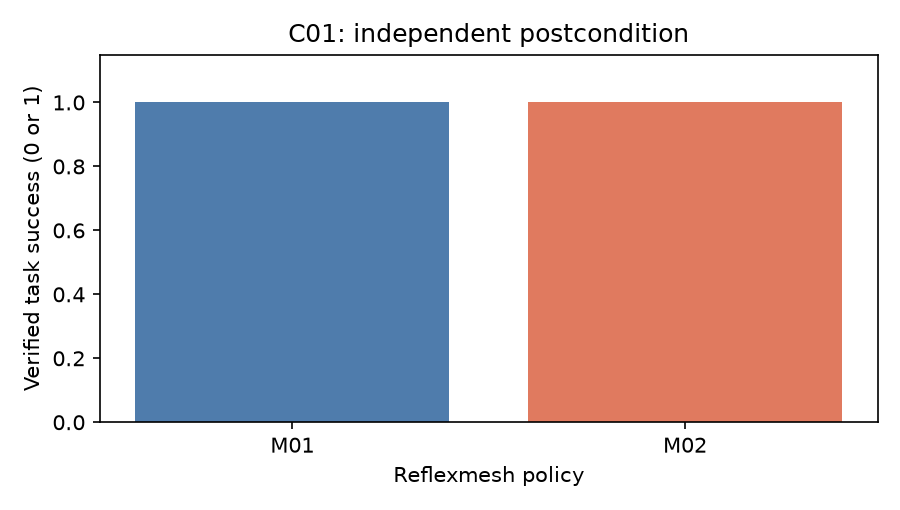

In [8]:
# Plot the independently verified outcomes from the two fresh policy runs.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Verified task success (0 or 1)")
ax.set_xlabel("Reflexmesh policy")
ax.set_title(f"{sample_case}: independent postcondition")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


For evaluation and transfer, these bars show fresh task-postcondition outcomes for M01 and M02 on C01, with success encoded as 1 and failure as 0. Read the case and seed before comparing them. In the single-run evaluation and transfer exercise on C01, this controlled episode illustrates policy behavior but is not a confidence interval and does not establish generalization to other software tasks;

## Results

**Answer:** The evaluation and transfer example executes 2 policies, M01 and M02, on C01; In the single-run evaluation and transfer exercise on C01, this matched sample demonstrates the API and independent verification, not performance over the benchmark.

The core matrix is saturated: In the single-run evaluation and transfer exercise on C01, seven methods solve all 1,200 episodes and only 71/1,440 method/case/variant cells vary by seed; For the evaluation and transfer example on C01, in semantic transfer, M04 solves 24/24 structural cases while M12 solves 21/24; In the single-run evaluation and transfer exercise on C01, the larger opaque semantic lane also favors M09 over M12; No learned-superiority claim is supported.

## Summary

For the evaluation and transfer example on C01, this evaluation and transfer example uses C01 to show behavior under one declared condition. For the evaluation and transfer example on C01, keep the measured outcome separate from claims about broader software-control intelligence.



## References
- [TOOLSANDBOX](https://arxiv.org/abs/2408.04682) - [SWE](https://arxiv.org/abs/2310.06770) - [TAU2](https://arxiv.org/abs/2506.07982)